# Báo Cáo Thực Nghiệm: Mạng Tích Chập 1D (1D CNN) Bằng PyTorch
## Bài Toán: Dự Đoán Nguy Cơ Tiểu Đường (Biomedical Tabular Classification)
**Học phần:** Phát triển Hệ thống Thông minh (Intelligent System Development)  
**Nhiệm vụ:** Assignment 04 - Ánh xạ kiến trúc 1D CNN sang PyTorch (`nn.Conv1d`, Autograd, DataLoader)  
**Dữ liệu:** `diabetes_prediction_dataset.csv` (100,000 mẫu lâm sàng)


In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print(f"Thiết bị tính toán: {device}")


Thiết bị tính toán: mps


### 1. Đọc & Tiền Xử Lý Dữ Liệu Đồng Bộ
Đảm bảo **thực nghiệm có kiểm soát** tuyệt đối: Cùng làm sạch, cùng chia train/test (`random_state=42`, tỷ lệ 80/20), cùng `StandardScaler`.


In [2]:
DATA_PATH = "../../../Assigment 02/diabetes/data/diabetes_prediction_dataset.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "src/Assigment 02/diabetes/data/diabetes_prediction_dataset.csv"

df_raw = pd.read_csv(DATA_PATH)
df_dedup = df_raw.drop_duplicates().copy()

df_clean = df_dedup[df_dedup['gender'] != 'Other'].copy()
df_clean['gender'] = (df_clean['gender'] == 'Male').astype(int)

smoking_map = {'never': 0, 'No Info': 0, 'former': 1, 'not current': 1, 'current': 2, 'ever': 2}
df_clean['smoking_history'] = df_clean['smoking_history'].map(smoking_map).fillna(0).astype(int)

features = ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']
target = 'diabetes'

X_data = df_clean[features].values.astype(np.float32)
y_data = df_clean[target].values.astype(np.float32)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.20, random_state=RANDOM_SEED, stratify=y_data
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# PyTorch Conv1d format: (N, C_in=1, L=8)
X_train_t = torch.tensor(X_train_scaled[:, np.newaxis, :], dtype=torch.float32)
y_train_t = torch.tensor(y_train[:, np.newaxis], dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled[:, np.newaxis, :], dtype=torch.float32)
y_test_t = torch.tensor(y_test[:, np.newaxis], dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=256, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=512, shuffle=False)

print(f"Kích thước tập huấn luyện: {len(train_loader.dataset)} mẫu")
print(f"Kích thước tập kiểm thử   : {len(test_loader.dataset)} mẫu")


Kích thước tập huấn luyện: 76902 mẫu
Kích thước tập kiểm thử   : 19226 mẫu


### 2. Định Nghĩa Kiến Trúc 1D CNN Bằng PyTorch (`nn.Module`)
Cấu trúc hoàn toàn tương đương với mô hình NumPy:
- `nn.Conv1d(1, 16, kernel_size=3)`
- `nn.ReLU()`
- `nn.Conv1d(16, 16, kernel_size=3)`
- `nn.ReLU()`
- `nn.MaxPool1d(2)`
- `nn.Flatten()`
- `nn.Linear(32, 8)`
- `nn.ReLU()`
- `nn.Linear(8, 1)`
- `nn.Sigmoid()`


In [3]:
class DiabetesCNN1D(nn.Module):
    def __init__(self):
        super(DiabetesCNN1D, self).__init__()
        self.network = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.Conv1d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Flatten(),
            nn.Linear(16 * 2, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

model = DiabetesCNN1D().to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Tổng số tham số học được của PyTorch 1D CNN: {total_params:,} tham số")


DiabetesCNN1D(
  (network): Sequential(
    (0): Conv1d(1, 16, kernel_size=(3,), stride=(1,))
    (1): ReLU()
    (2): Conv1d(16, 16, kernel_size=(3,), stride=(1,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Flatten(start_dim=1, end_dim=-1)
    (6): Linear(in_features=32, out_features=8, bias=True)
    (7): ReLU()
    (8): Linear(in_features=8, out_features=1, bias=True)
    (9): Sigmoid()
  )
)
Tổng số tham số học được của PyTorch 1D CNN: 1,121 tham số


### 3. Huấn Luyện Mô Hình Với PyTorch


In [4]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.003)
epochs = 12

history = {"loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

start_time = time.time()
print("Bắt đầu huấn luyện mô hình 1D CNN PyTorch...")

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(batch_y)
        
    epoch_loss = running_loss / len(train_loader.dataset)
    
    # Đánh giá kiểm thử
    model.eval()
    val_loss = 0.0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for val_x, val_y in test_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            preds = model(val_x)
            v_loss = criterion(preds, val_y)
            val_loss += v_loss.item() * len(val_y)
            all_preds.extend(preds.cpu().numpy().ravel())
            all_targets.extend(val_y.cpu().numpy().ravel())
            
    val_loss = val_loss / len(test_loader.dataset)
    val_binary = (np.array(all_preds) >= 0.5).astype(int)
    val_acc = accuracy_score(all_targets, val_binary)
    val_f1 = f1_score(all_targets, val_binary, zero_division=0)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} - Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

train_time = time.time() - start_time
print(f"\nHuấn luyện PyTorch hoàn tất trong: {train_time:.2f} giây!")


Bắt đầu huấn luyện mô hình 1D CNN PyTorch...


Epoch 01/12 - Train Loss: 0.1760 | Val Loss: 0.1092 | Val Acc: 0.9623 | Val F1: 0.7495


Epoch 02/12 - Train Loss: 0.1045 | Val Loss: 0.1018 | Val Acc: 0.9658 | Val F1: 0.7683


Epoch 03/12 - Train Loss: 0.0987 | Val Loss: 0.0980 | Val Acc: 0.9673 | Val F1: 0.7766


Epoch 04/12 - Train Loss: 0.0950 | Val Loss: 0.0965 | Val Acc: 0.9668 | Val F1: 0.7858


Epoch 05/12 - Train Loss: 0.0924 | Val Loss: 0.0942 | Val Acc: 0.9678 | Val F1: 0.7890


... (3 outputs left out)

Epoch 09/12 - Train Loss: 0.0870 | Val Loss: 0.0875 | Val Acc: 0.9710 | Val F1: 0.8052


Epoch 10/12 - Train Loss: 0.0863 | Val Loss: 0.0927 | Val Acc: 0.9697 | Val F1: 0.8048


Epoch 11/12 - Train Loss: 0.0866 | Val Loss: 0.0879 | Val Acc: 0.9713 | Val F1: 0.8070


Epoch 12/12 - Train Loss: 0.0854 | Val Loss: 0.0898 | Val Acc: 0.9701 | Val F1: 0.8036

Huấn luyện PyTorch hoàn tất trong: 24.56 giây!


### 4. Đánh Giá Toàn Diện & Trực Quan Hóa Kết Quả


=== KẾT QUẢ ĐÁNH GIÁ 1D CNN (PYTORCH) ===
• Accuracy : 0.9701
• Precision: 0.9576
• Recall   : 0.6922
• F1-Score : 0.8036
• ROC-AUC  : 0.9730
• Thời gian: 24.56 giây


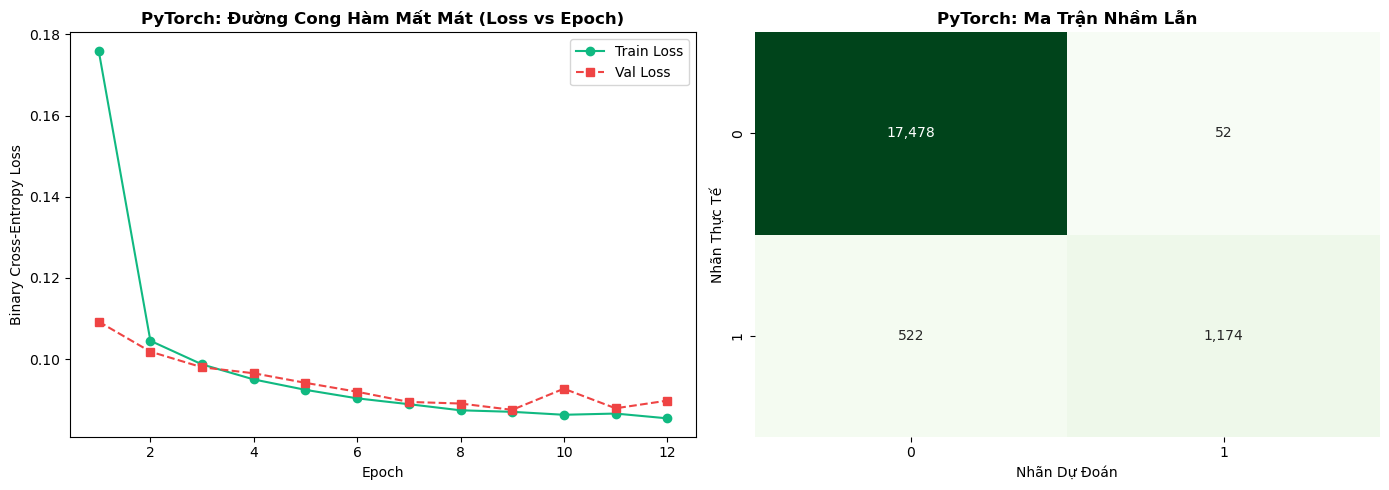

In [5]:
model.eval()
with torch.no_grad():
    y_prob = model(X_test_t.to(device)).cpu().numpy().ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print(f"=== KẾT QUẢ ĐÁNH GIÁ 1D CNN (PYTORCH) ===")
print(f"• Accuracy : {acc:.4f}")
print(f"• Precision: {prec:.4f}")
print(f"• Recall   : {rec:.4f}")
print(f"• F1-Score : {f1:.4f}")
print(f"• ROC-AUC  : {auc:.4f}")
print(f"• Thời gian: {train_time:.2f} giây")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, epochs + 1), history["loss"], 'o-', color='#10b981', label='Train Loss')
axes[0].plot(range(1, epochs + 1), history["val_loss"], 's--', color='#ef4444', label='Val Loss')
axes[0].set_title('PyTorch: Đường Cong Hàm Mất Mát (Loss vs Epoch)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('PyTorch: Ma Trận Nhầm Lẫn', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nhãn Dự Đoán')
axes[1].set_ylabel('Nhãn Thực Tế')

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/02_diabetes_pytorch_results.png", dpi=300)
plt.show()


### 5. Lưu Trữ Kết Quả Thực Nghiệm


In [6]:
results_df = pd.DataFrame([{
    "Framework": "PyTorch",
    "Dataset": "Diabetes (100k)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1": f1,
    "ROC_AUC": auc,
    "Train_Time_Sec": train_time,
    "Epochs": epochs,
    "Batch_Size": 256
}])

results_df.to_csv("../reports/model_results_pytorch.csv", index=False)
print("Đã lưu kết quả thành công vào ../reports/model_results_pytorch.csv")
results_df


Đã lưu kết quả thành công vào ../reports/model_results_pytorch.csv


,Framework,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Time_Sec,Epochs,Batch_Size
0,PyTorch,Diabetes (100k),0.970145,0.957586,0.692217,0.803559,0.972953,24.557744,12,256
